Hm0  = 5.99 m
Tm01 = 7.5 s
Tmz = 7.1 s
Tm-1,0 = 8.0 s
Tp   = 8.8 s
fp   = 0.114 Hz


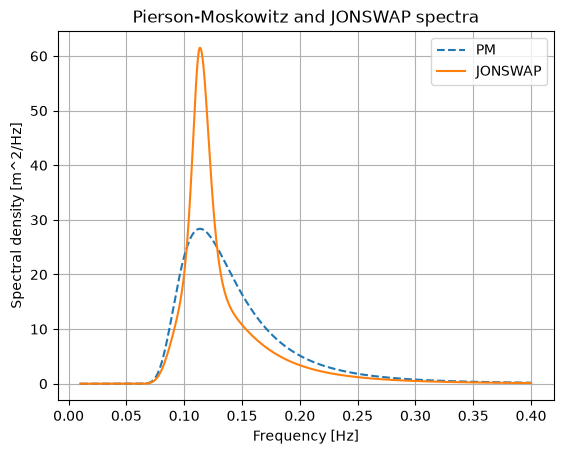

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D   # 3D-plots (bij nieuwere matplotlib niet meer nodig)
import scipy.optimize as opt              # curve fitting, bijv. opt.curve_fit
import scipy.stats as stats               # statistiek en verdelingen
import pandas as pd                       # als je met tabellen/CSV werkt



Tp = 8.8  # wave peak period [s]
fp = 1 / Tp  # wave peak frequency [Hz]
gamma = 3.3  # peak enhancement factor [-]
sigma2 = 0.09   # spectral width parameter for f > fp [-]
sigma1 = 0.07  # spectral width parameter for f <= fp [-]
A_gamma = 1-0.287 * np.log(gamma)  # normalization factor [-]
Hs = 6 

def PM (f):
    """Pierson-Moskowitz spectrum [m^2/Hz]"""
    return  5 / 16 * (Hs**2) * (fp ** 4) * (f ** -5) * np.exp(-5 / 4 * ((fp / f) ** 4))


def JONSWAP (f):
    """JONSWAP spectrum [m^2/Hz]"""
    S_PM = PM(f)
    sigma_f = np.where(f <= fp, sigma1, sigma2)
    r = np.exp(-((f - fp) ** 2) / (2 * (sigma_f ** 2) * (fp ** 2)))
    return A_gamma * S_PM * (gamma ** r)

plt.figure()
plt.title('Pierson-Moskowitz and JONSWAP spectra')
f = np.linspace(0.01, 0.4, 2000)
plt.plot(f, PM(f), label='PM', linestyle='--')
plt.plot(f, JONSWAP(f), label='JONSWAP')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Spectral density [m^2/Hz]')
plt.grid()
plt.legend()

E = JONSWAP(f)

# Ongeldige waarden en f = 0 eruit filteren
mask = np.isfinite(f) & np.isfinite(E) & (f > 0)
f, E = f[mask], E[mask]

def moment(n, f, E):
    return np.trapezoid(f**n * E, f)

m0  = moment(0, f, E)
m1  = moment(1, f, E)
m2  = moment(2, f, E)
mm1 = moment(-1, f, E)

Hm0  = 4 * np.sqrt(m0)            # significante golfhoogte
Tm01 = m0 / m1                    # gemiddelde periode
Tmz = np.sqrt(m0 / m2)           # Rice / zero-crossing periode
Tm10 = mm1 / m0                   # energieperiode (Tm-1,0)

fp = f[np.argmax(E)]              # piekfrequentie
Tp = 1 / fp                       # piekperiode

print(f"Hm0  = {Hm0:.2f} m")
print(f"Tm01 = {Tm01:.1f} s")
print(f"Tmz = {Tmz:.1f} s")
print(f"Tm-1,0 = {Tm10:.1f} s")
print(f"Tp   = {Tp:.1f} s")
print(f"fp   = {fp:.3f} Hz")